# Speculative decoding report — Qwen3-4B

Final tables and figures for the comparison in [`EXPERIMENTS.md`](../../EXPERIMENTS.md), computed from the
logs written by `python -m experiments.run_sweep` (record schemas: [`experiments/README.md`](../README.md)).

Edit **only the configuration cell** below, then *Run All*. Nothing else hardcodes run paths, `K` values,
datasets or methods.

| Section | Content |
|---|---|
| 1–2 | configuration, imports, plot style |
| 3–4 | log discovery / loading, validation and sanity checks |
| 5 | metric definitions and computation |
| 6 | **Table 1** — accepted length at `BASE_K` |
| 7 | **Figure 1** — position-wise conditional acceptance at `BASE_K` |
| 8 | **Figure 2** — accepted length and decode latency vs `K` |
| 9 | **Figure 3** — additional memory of the speculative machinery vs `K` |
| 10 | **Table 4** — GSM8K comparison with the EAGLE-3 paper (EAGLE-compatible τ) |
| 11 | supporting diagnostics |
| 12 | **Main Results** — accepted length at `BASE_K` (incl. bonus token), LaTeX table |

## 1. Configuration

In [1]:
# ---- Configuration: the only cell that needs editing --------------------------------------------
# Logs. LOG_DIR is either one run directory (contains manifest.json) or a directory with run
# directories below it. Relative paths are resolved against the repository root.
LOG_DIR = "experiments/results/DeepSpec_qwen3_4b_main_results"
RUNS = "latest"          # "latest" = newest run under LOG_DIR; "all" = merge every run; or a list of run ids

K_VALUES = [4, 7, 8, 12, 16]  # draft lengths to report
BASE_K = 7               # K used for the fixed-K comparisons (Table 1, Figures 1 and 3)
K_FIG2 = [4, 8, 12, 16]  # draft lengths shown in Figure 2 (accepted length + latency per step)

DATASETS = ["gsm8k", "math500", "aime25"]       # order of columns / panels; missing ones are skipped
METHODS = ["eagle3", "dflash", "dspark"]        # speculative methods, in display order
AR_METHOD = "ar"                                # autoregressive baseline (logged with k = 0)

FOCUS_METHOD = "dspark"                         # method whose relative improvement is reported
BASELINES = ["eagle3", "dflash"]                # ... relative to these (Table 1)
REF_METHOD = "dflash"                           # reference for the Figure 2 annotations

TABLE4_DATASET = "gsm8k"
TABLE4_SELECT_BY = "speedup"                    # pick the best K per method by "speedup" or "tau"

METHOD_NAMES = {"ar": "AR (Qwen3-4B)", "eagle3": "EAGLE-3", "dflash": "DFlash", "dspark": "DSpark"}
DATASET_NAMES = {"gsm8k": "GSM8K", "math500": "Math500", "aime25": "AIME25"}

OUTPUT_DIR = None        # None = "<LOG_DIR or the single run dir>/report"; False = do not save anything
SAVE_FORMATS = ("pdf", "png")

# ---- Values copied from external papers (NOT measured here) -------------------------------------
# DSpark paper, main table, Qwen3-4B target, math benchmarks: average accepted length incl. the bonus
# token, in the paper's own setting (its block size / sampling settings, not necessarily ours).
DSPARK_PAPER_TABLE1 = {
    "eagle3": {"gsm8k": 5.14, "math500": 4.62, "aime25": 3.92},
    "dflash": {"gsm8k": 5.40, "math500": 4.85, "aime25": 4.15},
    "dspark": {"gsm8k": 6.11, "math500": 5.70, "aime25": 4.89},
}
# EAGLE-3 paper (Li et al., 2025), GSM8K. Not in the repository: fill in from the paper, together
# with the target model and temperature the number refers to. None renders as "—".
EAGLE3_PAPER_GSM8K = {
    "target_model": None,
    "temperature": None,
    "acceptance_length": None,   # τ
    "speedup": None,
}

## 2. Imports and plotting style

In [2]:
import json
import warnings
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display


def find_repo_root(start: Path) -> Path:
    for path in [start, *start.parents]:
        if (path / "experiments").is_dir() and (path / "deepspec").is_dir():
            return path
    raise FileNotFoundError("repository root (with experiments/ and deepspec/) not found")


REPO_ROOT = find_repo_root(Path.cwd().resolve())


def resolve(path) -> Path:
    path = Path(path)
    return path if path.is_absolute() else REPO_ROOT / path


GIB = 1024 ** 3
PHASES = ["draft_ms", "verification_ms", "update_ms", "commit_ms"]
PHASE_NAMES = {"draft_ms": "draft", "verification_ms": "verification",
               "update_ms": "drafter update", "commit_ms": "commit / other"}

# Categorical palette in a fixed order (method identity follows the method, never its rank);
# markers are a second, non-color encoding. AR is a neutral reference, not a series.
_SERIES = ["#2a78d6", "#1baf7a", "#eb6834", "#eda100", "#e87ba4", "#6250d6", "#008300", "#e34948"]
_MARKERS = ["^", "o", "s", "D", "v", "P", "X", "h"]
AR_COLOR = "#77766f"
INK, MUTED, GRID = "#1f1e1b", "#6b6a64", "#e4e3dd"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    # Jupyter backends may default to a transparent figure; saved figures must be opaque white.
    "figure.facecolor": "white", "savefig.facecolor": "white", "savefig.transparent": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
})
pd.set_option("display.precision", 3)

## 3. Log discovery and loading

A *run* is a directory with `manifest.json`, `samples.<method>.rank<r>.jsonl`, `steps.<method>.rank<r>.jsonl`,
`summary.jsonl` and `workers/<method>.rank<r>.json`. With `RUNS = "all"`, runs are merged; if the same
`(method, dataset, k)` appears in several runs, the newest run wins (reported below), and runs with different
generation settings are refused, because their numbers would not be comparable.

In [3]:
def read_jsonl(path: Path) -> list[dict]:
    with open(path, encoding="utf-8") as handle:
        return [json.loads(line) for line in handle if line.strip()]


def discover_runs(log_dir: Path) -> list[Path]:
    if (log_dir / "manifest.json").is_file():
        return [log_dir]
    return sorted(p.parent for p in log_dir.rglob("manifest.json"))


def load_run(run_dir: Path) -> dict:
    manifest = json.loads((run_dir / "manifest.json").read_text())
    run_id = manifest.get("run_id", run_dir.name)

    def frame(rows):
        df = pd.DataFrame(rows)
        if len(df):
            df.insert(0, "run_id", run_id)
        return df

    samples = frame([r for p in sorted(run_dir.glob("samples.*.jsonl")) for r in read_jsonl(p)])
    steps = frame([r for p in sorted(run_dir.glob("steps.*.jsonl")) for r in read_jsonl(p)])
    summary_path = run_dir / "summary.jsonl"
    summary = frame(read_jsonl(summary_path) if summary_path.is_file() else [])
    workers = frame([json.loads(p.read_text()) for p in sorted((run_dir / "workers").glob("*.json"))])
    return {"run_id": run_id, "dir": run_dir, "manifest": manifest, "samples": samples,
            "steps": steps, "summary": summary, "workers": workers}


def select_runs(log_dir: Path, runs) -> list[dict]:
    found = discover_runs(log_dir)
    if not found:
        raise FileNotFoundError(f"no run (manifest.json) under {log_dir}")
    loaded = sorted((load_run(d) for d in found), key=lambda r: r["manifest"].get("start_time", ""))
    if runs == "latest":
        return loaded[-1:]
    if runs == "all":
        return loaded
    by_id = {r["run_id"]: r for r in loaded}
    missing = [r for r in runs if r not in by_id]
    if missing:
        raise KeyError(f"runs not found under {log_dir}: {missing}; available: {list(by_id)}")
    return [by_id[r] for r in runs]


GROUP = ["method", "dataset", "k"]
SAMPLE_KEY = GROUP + ["sample_idx"]


def merge_runs(runs: list[dict]) -> dict:
    """Concatenates runs; for a (method, dataset, k) present in several runs, keeps the newest."""
    gens = {r["run_id"]: r["manifest"]["config"].get("generation") for r in runs}
    if len({json.dumps(g, sort_keys=True) for g in gens.values()}) > 1:
        raise ValueError(f"runs use different generation settings, not comparable: {gens}")
    owner = {}  # (method, dataset, k) -> run_id of the newest run that has it
    for r in runs:  # sorted oldest -> newest
        if len(r["samples"]):
            for key in r["samples"][GROUP].drop_duplicates().itertuples(index=False):
                if key in owner:
                    warnings.warn(f"{tuple(key)} in runs {owner[key]} and {r['run_id']}; using {r['run_id']}")
                owner[tuple(key)] = r["run_id"]
    keep = pd.DataFrame([(*k, v) for k, v in owner.items()], columns=GROUP + ["run_id"])

    def cat(name, on=GROUP + ["run_id"]):
        df = pd.concat([r[name] for r in runs if len(r[name])], ignore_index=True)
        return df.merge(keep, on=on) if len(df) else df

    workers = pd.concat([r["workers"] for r in runs if len(r["workers"])], ignore_index=True)
    workers = workers.merge(keep[["method", "run_id"]].drop_duplicates(), on=["method", "run_id"])
    return {"runs": runs, "samples": cat("samples"), "steps": cat("steps"), "summary": cat("summary"),
            "workers": workers, "generation": next(iter(gens.values()))}


LOG_PATH = resolve(LOG_DIR)
data = merge_runs(select_runs(LOG_PATH, RUNS))
samples, steps, summary, workers = data["samples"], data["steps"], data["summary"], data["workers"]

if OUTPUT_DIR is False:
    OUT_DIR = None
else:
    OUT_DIR = resolve(OUTPUT_DIR) if OUTPUT_DIR else (
        data["runs"][0]["dir"] if len(data["runs"]) == 1 else LOG_PATH) / "report"
    OUT_DIR.mkdir(parents=True, exist_ok=True)

run_table = pd.DataFrame([{
    "run_id": r["run_id"], "git commit": r["manifest"].get("git", {}).get("commit", "")[:9],
    "dirty": r["manifest"].get("git", {}).get("dirty"),
    "methods": ", ".join(sorted(r["samples"]["method"].unique())) if len(r["samples"]) else "",
    "K in logs": sorted(int(k) for k in r["samples"]["k"].unique()) if len(r["samples"]) else [],
    "GPU": ", ".join(r["workers"]["gpu_name"].unique()) if len(r["workers"]) else "",
} for r in data["runs"]])
display(run_table)
display(Markdown(f"Generation settings: `{data['generation']}` · samples: {len(samples):,} · "
                 f"steps: {len(steps):,} · outputs: `{OUT_DIR}`"))

,run_id,git commit,dirty,methods,K in logs,GPU
0,qwen3_4b_main_merged,c3a07aec7,True,"ar, dflash, dspark, eagle3","[0, 4, 7, 8, 12, 16]",NVIDIA GeForce RTX 3090


Generation settings: `{'temperature': 1.0, 'max_new_tokens': 2048, 'seed': 980406, 'enable_thinking': False}` · samples: 2,080 · steps: 496,191 · outputs: `/media/atem/Data/HSE_videos/PROJECTS/DeepSpec/experiments/results/DeepSpec_qwen3_4b_main_results/report`

## 4. Validation and sanity checks

Coverage of the requested matrix, and the record invariants documented in `experiments/README.md`, recomputed
from the stored records. A failed check does not stop the notebook, but the affected numbers should not be
reported before the cause is understood.

In [4]:
checks = []


def check(name, ok, detail=""):
    checks.append({"check": name, "status": "ok" if ok else "FAIL", "detail": str(detail)[:200]})
    if not ok:
        warnings.warn(f"{name}: {detail}")


# ---- Requested matrix -----------------------------------------------------------------------------
present = set(map(tuple, samples[GROUP].drop_duplicates().itertuples(index=False)))
logged_k = sorted({k for m, _, k in present if m != AR_METHOD})
check("BASE_K is in K_VALUES", BASE_K in K_VALUES, f"BASE_K={BASE_K}, K_VALUES={K_VALUES}")
check("K_VALUES are present in the logs", set(K_VALUES) <= set(logged_k),
      f"requested {K_VALUES}, logged {logged_k}")
missing = [(m, d, k) for m in METHODS for d in DATASETS for k in K_VALUES if (m, d, k) not in present]
missing += [(AR_METHOD, d, 0) for d in DATASETS if (AR_METHOD, d, 0) not in present]
check("all requested (method, dataset, K) combinations present", not missing, missing)
extra_methods = sorted({m for m, _, _ in present} - set(METHODS) - {AR_METHOD})
if extra_methods:
    print(f"note: methods in the logs but not in METHODS (ignored): {extra_methods}")
if sorted(set(logged_k) - set(K_VALUES)):
    print(f"note: K values in the logs but not in K_VALUES (ignored): {sorted(set(logged_k) - set(K_VALUES))}")

# Restrict everything below to the configured matrix.
in_scope = lambda df: df[(df["dataset"].isin(DATASETS)) & (
    ((df["method"] == AR_METHOD) & (df["k"] == 0)) | (df["method"].isin(METHODS) & df["k"].isin(K_VALUES)))]
samples, steps = in_scope(samples).copy(), in_scope(steps).copy()
DS = [d for d in DATASETS if d in set(samples["dataset"])]
MS = [m for m in METHODS if m in set(samples["method"])]
KS = sorted(k for k in K_VALUES if k in set(samples.loc[samples["method"] != AR_METHOD, "k"]))
HAS_AR = AR_METHOD in set(samples["method"])

# ---- Record invariants --------------------------------------------------------------------------
agg = steps.groupby(SAMPLE_KEY).agg(n=("step", "size"), committed=("committed", "sum"),
                                     **{p: (p, "sum") for p in PHASES})
s = samples.set_index(SAMPLE_KEY).join(agg[["n", "committed"]])
s["n"] = s["n"].fillna(0)
check("one step record per speculative step", (s["n"] == s["num_steps"]).all(),
      s.index[s["n"] != s["num_steps"]].tolist()[:5])
stop = s["stop_reason"] == "stop_token"
tot = 1 + s["committed"].fillna(0)
ok = np.where(stop, tot == s["generated_len"], tot >= s["generated_len"])
check("1 + Σ committed == generated_len (≥ when length-limited)", ok.all(), s.index[~ok].tolist()[:5])
STEP_TIMING = samples["draft_ms"].notna().all()
check("per-step timing recorded (step_timing=true)", STEP_TIMING,
      "phase latencies are null; latency figures will be empty")
if STEP_TIMING:
    diff = max(float((s[p] - agg[p].reindex(s.index).fillna(0)).abs().max()) for p in PHASES)
    check("sample phase sums == Σ step phases", diff < 1e-3, f"max |diff| = {diff:.2e} ms")
st = steps
check("0 ≤ accepted ≤ effective_len ≤ drafted_len",
      ((st["accepted"] >= 0) & (st["accepted"] <= st["effective_len"]) & (st["effective_len"] <= st["drafted_len"])).all())
check("committed ∈ {accepted, accepted + 1}", (st["committed"] - st["accepted"]).isin([0, 1]).all())
check("requested_len == K", (st["requested_len"] == st["k"]).all())
check("drafted_len ≤ K", (st["drafted_len"] <= st["k"]).all())

# ---- Comparability across methods ----------------------------------------------------------------
sha = samples.groupby(["dataset", "sample_idx"])["prompt_sha1"].nunique()
check("same prompt for a sample_idx across methods / K", (sha == 1).all(), sha[sha > 1].index.tolist()[:5])
sets = samples.groupby(GROUP)["sample_idx"].apply(frozenset)
same = sets.groupby(level="dataset").apply(lambda x: x.nunique() == 1)
check("same sample set for every (method, K) within a dataset", same.all(), same[~same].index.tolist())

# ---- Summary parity (summary.jsonl was written online; recompute from the step records) ----------
if len(summary):
    g = steps.groupby(GROUP).agg(n=("step", "size"), committed=("committed", "sum"), accepted=("accepted", "sum"))
    worst = 0.0
    for row in summary.itertuples():
        key = (row.method, row.dataset, row.k)
        if key not in g.index:
            continue
        native = g.loc[key, "committed"] / g.loc[key, "n"]
        ds_block = row.deepspec_metrics if isinstance(getattr(row, "deepspec_metrics", None), dict) else row.metrics
        worst = max(worst, abs(native - ds_block["acceptance_length"]))
    check("summary.jsonl acceptance_length == Σ committed / Σ steps", worst < 1e-9, f"max |diff| = {worst:.2e}")

# ---- Informational -------------------------------------------------------------------------------
lim = samples.groupby(GROUP)["stop_reason"].apply(lambda x: (x == "length").mean())
check("share of length-limited samples ≤ 50% (outputs not dominated by truncation)", (lim <= 0.5).all(),
      f"max share {lim.max():.0%} at {lim.idxmax()}; max_new_tokens={data['generation'].get('max_new_tokens')}")
n_per = samples.groupby(GROUP).size()
check("≥ 30 samples per (method, dataset, K)", (n_per >= 30).all(), f"min {n_per.min()} samples")

display(pd.DataFrame(checks).style.apply(
    lambda c: ["color: #c0392b; font-weight: bold" if v == "FAIL" else "" for v in c], subset=["status"]))

/tmp/ipykernel_858525/4030452477.py:7: UserWarning: share of length-limited samples ≤ 50% (outputs not dominated by truncation): max share 77% at ('dspark', 'aime25', np.int64(4)); max_new_tokens=2048
  warnings.warn(f"{name}: {detail}")


,check,status,detail
0,BASE_K is in K_VALUES,ok,"BASE_K=7, K_VALUES=[4, 7, 8, 12, 16]"
1,K_VALUES are present in the logs,ok,"requested [4, 7, 8, 12, 16], logged [4, 7, 8, 12, 16]"
2,"all requested (method, dataset, K) combinations present",ok,[]
3,one step record per speculative step,ok,[]
4,1 + Σ committed == generated_len (≥ when length-limited),ok,[]
5,per-step timing recorded (step_timing=true),ok,phase latencies are null; latency figures will be empty
6,sample phase sums == Σ step phases,ok,max |diff| = 0.00e+00 ms
7,0 ≤ accepted ≤ effective_len ≤ drafted_len,ok,
8,"committed ∈ {accepted, accepted + 1}",ok,
9,requested_len == K,ok,


## 5. Metric definitions

Field semantics, verified in `deepspec/eval/base_evaluator.py` (`verify_draft_tokens`, `generate_decoding_sample`),
`experiments/instrumentation.py`, `experiments/records.py` and `experiments/metrics.py`:

| Field | Meaning |
|---|---|
| `requested_len` | `K` (0 for AR) |
| `drafted_len` | tokens the drafter produced; `< K` only when the EAGLE-3 chain samples a stop token |
| `effective_len` | draft tokens verified (DeepSpec's `proposal_lengths`): `drafted_len`, truncated after an *accepted* stop token |
| `accepted` | length of the accepted draft prefix (rejection sampling, `cumprod` of per-position accepts) — **excludes** the bonus token |
| `committed` | tokens appended this step: `accepted + 1` (bonus / corrected target token), or `accepted` when an accepted draft token is a stop token |
| `generated_len`, `num_steps` | output tokens incl. the first token sampled at prefill (trimmed to `max_new_tokens`); number of verifications |
| `draft_ms` / `verification_ms` / `update_ms` / `commit_ms` | GPU-stream CUDA-event intervals of `propose` / target forward + acceptance / drafter state update / the rest of the step (KV crop, bookkeeping); they tile the decode timeline |
| `target_prefill_ms`, `init_context_ms` | prompt forward + first token; drafter initialisation from the prompt — both **excluded** from decode latency |
| `wall_ms` | host clock over the whole sample (prefill included); a cross-check only |
| `prefill_peak_bytes`, `decode_peak_bytes` | `max_memory_allocated()` (absolute, weights included) during prefill + `init_context`, and during decode (stats reset in between) |
| summary `deepspec_metrics.acceptance_length` | DeepSpec's: Σ `committed` / Σ steps — **includes** the bonus token |
| summary `metrics.acceptance_length` | ours: Σ `accepted` / Σ steps — excludes the bonus token |
| `accept_rates_by_position[i]` | steps with `accepted > i` / steps with `effective_len > i`: prefix **survival**, not conditional acceptance |

Metrics used in the report (all ratio-of-sums over every step / sample of a `(method, dataset, K)` group, so long
generations weigh by their number of steps / tokens rather than one vote per sample):

| Metric | Definition | Used in |
|---|---|---|
| **accepted length** `A` | Σ `committed` / Σ steps — DeepSpec's native `acceptance_length`, bonus token included | Table 1, Figure 2a |
| acceptance rate | Σ `committed` / (Σ `effective_len` + Σ steps) — DeepSpec's `verify_rate`, bonus included | diagnostics |
| draft acceptance rate | Σ `accepted` / Σ `effective_len` (bonus excluded, labelled as such) | diagnostics |
| conditional acceptance at position `i` | #steps with `accepted ≥ i` / #steps with `accepted ≥ i−1` and `effective_len ≥ i` | Figure 1 |
| decode latency per token | Σ (`draft`+`verification`+`update`+`commit`) / Σ (`generated_len` − 1) | Figure 2b, Table 4 |
| decode latency per round | same numerator / Σ steps | Figure 2b |
| speedup | AR decode ms/token ÷ method decode ms/token (same dataset, same prompts) | Table 4, diagnostics |
| **EAGLE-compatible τ** | Σ `generated_len` / Σ `num_steps` — **Table 4 only** | Table 4 |

The decode-token denominator `generated_len − 1` excludes the token sampled at prefill (its cost is in
`target_prefill_ms`) and counts only tokens kept in the output: tokens committed past `max_new_tokens` and then
trimmed are work without output, as in a real deployment.

In [5]:
def safe_div(a, b):
    return np.where(np.asarray(b) > 0, np.asarray(a, dtype=float) / np.where(np.asarray(b) > 0, b, 1), np.nan)


samples["decode_ms"] = samples[PHASES].sum(axis=1, min_count=len(PHASES))
# Whole generation on the GPU timeline: target prefill + drafter init_context + decode.
samples["total_ms"] = samples["target_prefill_ms"] + samples["init_context_ms"].fillna(0) + samples["decode_ms"]
samples["decode_tokens"] = (samples["generated_len"] - 1).clip(lower=0)
samples["peak_bytes"] = samples[["prefill_peak_bytes", "decode_peak_bytes"]].max(axis=1)
samples["context_len"] = samples["prompt_len"] + samples["generated_len"]


def group_metrics(samples: pd.DataFrame, steps: pd.DataFrame) -> pd.DataFrame:
    st = steps.groupby(GROUP).agg(steps=("step", "size"), committed=("committed", "sum"),
                                  accepted=("accepted", "sum"), effective=("effective_len", "sum"),
                                  drafted=("drafted_len", "sum"))
    sa = samples.groupby(GROUP).agg(
        n_samples=("sample_idx", "size"), num_steps=("num_steps", "sum"), generated=("generated_len", "sum"),
        decode_tokens=("decode_tokens", "sum"), decode_ms=("decode_ms", "sum"), total_ms=("total_ms", "sum"),
        **{p: (p, "sum") for p in PHASES},
        prefill_ms=("target_prefill_ms", "mean"), init_context_ms=("init_context_ms", "mean"),
        prompt_len=("prompt_len", "mean"), generated_len=("generated_len", "mean"),
        length_limited=("stop_reason", lambda x: (x == "length").mean()),
        peak_gib=("peak_bytes", lambda x: x.mean() / GIB), peak_max_gib=("peak_bytes", lambda x: x.max() / GIB))
    g = sa.join(st, how="left")
    g["accept_len"] = safe_div(g["committed"], g["steps"])            # native, bonus included
    g["accepted_draft_per_step"] = safe_div(g["accepted"], g["steps"])  # bonus excluded
    g["eff_draft_len"] = safe_div(g["effective"], g["steps"])
    g["acceptance_rate"] = safe_div(g["committed"], g["effective"] + g["steps"])
    g["draft_acceptance_rate"] = safe_div(g["accepted"], g["effective"])
    g["tau_eagle"] = safe_div(g["generated"], g["num_steps"])          # Table 4 only
    g["ms_per_token"] = safe_div(g["decode_ms"], g["decode_tokens"])
    g["ms_per_round"] = safe_div(g["decode_ms"], g["steps"])
    g["ms_per_step_total"] = safe_div(g["total_ms"], g["num_steps"])  # DSpark paper: generation time / steps
    for p in PHASES:
        g[p + "_per_round"] = safe_div(g[p], g["steps"])
        g[p + "_per_token"] = safe_div(g[p], g["decode_tokens"])
    g["tokens_per_s"] = 1e3 / g["ms_per_token"]
    g = g.reset_index()
    if HAS_AR:
        ar = g[g["method"] == AR_METHOD].set_index("dataset")["ms_per_token"]
        g["speedup"] = g["dataset"].map(ar) / g["ms_per_token"]
    else:
        g["speedup"] = np.nan
    return g


G = group_metrics(samples, steps)


def metric(method, dataset, k, col):
    row = G[(G["method"] == method) & (G["dataset"] == dataset) & (G["k"] == k)]
    return float(row[col].iloc[0]) if len(row) else np.nan


def macro(method, k, col):
    """Unweighted mean over datasets: each dataset counts once, whatever its sample count."""
    return float(np.mean([metric(method, d, k, col) for d in DS]))


def rel(a, b):
    return 100.0 * (a - b) / b


def name(m):
    return METHOD_NAMES.get(m, m)


def dname(d):
    return DATASET_NAMES.get(d, d)


STYLE = {m: {"color": _SERIES[i % len(_SERIES)], "marker": _MARKERS[i % len(_MARKERS)]}
         for i, m in enumerate(METHODS)}
STYLE[AR_METHOD] = {"color": AR_COLOR, "marker": "x"}


def save(fig, stem):
    if OUT_DIR is not None:
        for fmt in SAVE_FORMATS:
            fig.savefig(OUT_DIR / f"{stem}.{fmt}", facecolor="white", transparent=False)


def save_table(df, stem):
    if OUT_DIR is not None:
        df.to_csv(OUT_DIR / f"{stem}.csv")


def legend_below(fig, methods, ar=False, extra=()):
    handles = [plt.Line2D([], [], color=STYLE[m]["color"], marker=STYLE[m]["marker"], label=name(m)) for m in methods]
    if ar:
        handles.append(plt.Line2D([], [], color=AR_COLOR, ls="--", label=name(AR_METHOD)))
    handles += list(extra)
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.02))


cols = ["method", "dataset", "k", "n_samples", "steps", "accept_len", "eff_draft_len", "ms_per_token",
        "ms_per_round", "speedup", "generated_len", "length_limited"]
display(G[cols].sort_values(["dataset", "method", "k"]).reset_index(drop=True))

,method,dataset,k,n_samples,steps,accept_len,eff_draft_len,ms_per_token,ms_per_round,speedup,generated_len,length_limited
0,ar,aime25,0,30,52317,1.000,0.000,57.888,57.868,1.000,1744.300,0.600
1,dflash,aime25,4,30,16869,3.227,3.999,22.816,73.556,2.537,1813.767,0.667
2,dflash,aime25,7,30,13027,4.062,6.997,18.162,73.691,3.187,1762.900,0.533
3,dflash,aime25,8,30,13367,4.105,7.998,18.010,73.822,3.214,1827.400,0.667
4,dflash,aime25,12,30,13691,3.919,11.992,18.930,74.113,3.058,1787.733,0.500
5,dflash,aime25,16,30,14632,3.664,15.993,20.507,75.050,2.823,1785.933,0.633
6,dspark,aime25,4,30,15024,3.805,3.999,20.089,76.359,2.882,1904.533,0.767
7,dspark,aime25,7,30,11086,4.930,6.997,15.759,77.613,3.673,1821.000,0.567
8,dspark,aime25,8,30,10639,5.217,7.997,15.011,78.190,3.856,1848.233,0.633
9,dspark,aime25,12,30,11201,4.901,11.996,16.303,79.772,3.551,1827.967,0.700


## 6. Table 1 — Main speculative decoding results (`K = BASE_K`)

Average accepted length per decoding round, **A = Σ committed / Σ rounds** (DeepSpec's native
`acceptance_length`; the target-generated bonus / corrected token is included, so `A ≤ K + 1`). Higher is better;
the best value per column is bold. Macro average = unweighted mean over datasets (only when all datasets are
present for that method).

Relative improvement of the focus method: (A<sub>focus</sub> − A<sub>baseline</sub>) / A<sub>baseline</sub> × 100%;
its macro average is the mean of the per-dataset relative improvements.

In [6]:
def table1(k: int) -> pd.DataFrame:
    t = pd.DataFrame({dname(d): [metric(m, d, k, "accept_len") for m in MS] for d in DS},
                     index=[name(m) for m in MS])
    t.index.name = f"Drafter (K={k})"
    t["Macro avg"] = t.mean(axis=1, skipna=False) if len(DS) > 1 else np.nan
    return t


def bold_max(col):
    return ["font-weight: bold" if np.isfinite(v) and v == np.nanmax(col) else "" for v in col]


T1 = table1(BASE_K)
display(Markdown(f"**Table 1.** Average accepted length (incl. bonus token), Qwen3-4B target, K = {BASE_K}."))
display(T1.style.apply(bold_max).format("{:.2f}", na_rep="—"))
save_table(T1, f"table1_accept_len_K{BASE_K}")

if FOCUS_METHOD in MS:
    rows = {}
    for b in [b for b in BASELINES if b in MS and b != FOCUS_METHOD]:
        r = {dname(d): rel(metric(FOCUS_METHOD, d, BASE_K, "accept_len"), metric(b, d, BASE_K, "accept_len"))
             for d in DS}
        r["Macro avg"] = np.mean(list(r.values())) if len(DS) > 1 else np.nan
        rows[f"{name(FOCUS_METHOD)} vs {name(b)}"] = r
    T1_rel = pd.DataFrame(rows).T
    display(Markdown(f"Relative improvement of {name(FOCUS_METHOD)} in accepted length, %:"))
    display(T1_rel.style.format("{:+.1f}%", na_rep="—"))
    save_table(T1_rel, f"table1_rel_improvement_K{BASE_K}")

paper = pd.DataFrame({dname(d): [DSPARK_PAPER_TABLE1.get(m, {}).get(d, np.nan) for m in MS] for d in DS},
                     index=[name(m) for m in MS])
if paper.notna().any().any():
    display(Markdown("Reference only — **values copied from the DSpark paper** (its own setting), and our "
                     f"measurement at K = {BASE_K} relative to them:"))
    display(pd.concat({"paper": paper, "ours / paper": T1[paper.columns] / paper}, axis=1)
            .style.format("{:.2f}", na_rep="—"))

**Table 1.** Average accepted length (incl. bonus token), Qwen3-4B target, K = 7.

,GSM8K,Math500,AIME25,Macro avg
Drafter (K=7),,,,
EAGLE-3,5.00,4.48,3.81,4.43
DFlash,5.39,4.91,4.06,4.79
DSpark,5.93,5.82,4.93,5.56


Relative improvement of DSpark in accepted length, %:

,GSM8K,Math500,AIME25,Macro avg
DSpark vs EAGLE-3,+18.5%,+29.9%,+29.5%,+26.0%
DSpark vs DFlash,+10.0%,+18.4%,+21.4%,+16.6%


Reference only — **values copied from the DSpark paper** (its own setting), and our measurement at K = 7 relative to them:

## 7. Figure 1 — Position-wise conditional acceptance (`K = BASE_K`)

For draft position `i = 1 … K`:

$$P(\text{position } i \text{ accepted} \mid \text{positions } 1,\dots,i-1 \text{ accepted})
= \frac{\#\{\text{rounds}: \text{accepted} \ge i\}}{\#\{\text{rounds}: \text{accepted} \ge i-1,\ \text{effective\_len} \ge i\}}.$$

**Exactly reconstructable from the step logs.** Verification accepts a *prefix*
(`accept_prefix_mask = cumprod(accept_mask)`), so "positions 1…i−1 accepted" ⇔ `accepted ≥ i−1`, and position `i`
was actually verified iff `effective_len ≥ i`. Rounds whose draft ended earlier (EAGLE-3 chain stopped at a stop
token; truncation after an accepted stop token) are excluded from the denominator at the positions they did not
verify. The per-round accept mask beyond the first rejection is not logged, but it is not needed: those positions
are by definition not in the conditional's denominator.

This differs from DeepSpec's `accept_rates_by_position` (prefix *survival* `P(accepted ≥ i)`, which decays
multiplicatively by construction); the two are compared in §11. Shaded bands are 95% Wilson intervals over rounds
(rounds within a sample are not independent, so the bands are optimistic). The number of rounds reaching the last
positions is printed below the figure.

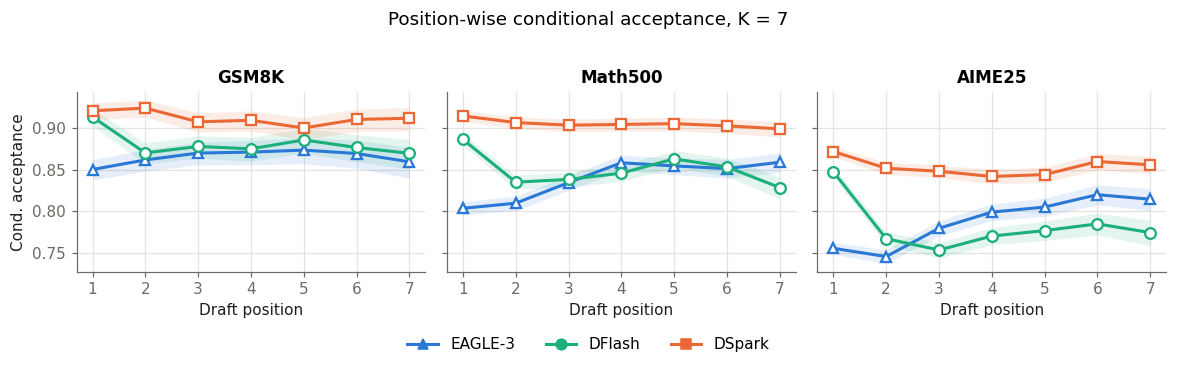

Rounds in the denominator (`reached`) per position:

position             1      2     3     4     5     6     7
GSM8K   EAGLE-3   3234   2744  2358  2046  1776  1545  1336
        DFlash    2973   2707  2347  2054  1791  1579  1379
        DSpark    2857   2625  2417  2190  1988  1781  1618
Math500 EAGLE-3  10000   8030  6497  5413  4635  3956  3364
        DFlash    8699   7701  6425  5378  4541  3910  3332
        DSpark    7347   6713  6079  5489  4955  4481  4035
AIME25  EAGLE-3  14312  10811  8059  6278  5013  4034  3307
        DFlash   13027  11037  8464  6376  4907  3809  2986
        DSpark   11086   9662  8226  6973  5869  4951  4255

In [7]:
def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    with np.errstate(invalid="ignore", divide="ignore"):
        p = k / n
        d = 1 + z * z / n
        c = (p + z * z / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h


def position_acceptance(st: pd.DataFrame, k: int) -> pd.DataFrame:
    acc, eff = st["accepted"].to_numpy()[:, None], st["effective_len"].to_numpy()[:, None]
    pos = np.arange(1, k + 1)[None, :]
    num = (acc >= pos).sum(0)
    den = ((acc >= pos - 1) & (eff >= pos)).sum(0)
    surv_den = (eff >= pos).sum(0)
    lo, hi = wilson(num, den)
    return pd.DataFrame({"position": pos[0], "accepted": num, "reached": den,
                         "conditional": safe_div(num, den), "lo": lo, "hi": hi,
                         "survival": safe_div(num, surv_den)})


POS = {(m, d, k): position_acceptance(steps[(steps["method"] == m) & (steps["dataset"] == d) & (steps["k"] == k)], k)
       for m in MS for d in DS for k in KS}


def plot_conditional(k: int):
    fig, axes = plt.subplots(1, len(DS), figsize=(3.6 * len(DS), 3.1), sharey=True, squeeze=False)
    for ax, d in zip(axes[0], DS):
        for m in MS:
            p = POS.get((m, d, k))
            if p is None or p["reached"].sum() == 0:
                continue
            ax.fill_between(p["position"], p["lo"], p["hi"], color=STYLE[m]["color"], alpha=0.12, lw=0)
            ax.plot(p["position"], p["conditional"], **STYLE[m], markerfacecolor="white", markeredgewidth=1.5)
        ax.set_title(dname(d))
        ax.set_xticks(range(1, k + 1))
        ax.set_xlabel("Draft position")
    axes[0, 0].set_ylabel("Cond. acceptance")
    legend_below(fig, MS)
    fig.suptitle(f"Position-wise conditional acceptance, K = {k}", y=1.02)
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    return fig


if BASE_K in KS:
    fig = plot_conditional(BASE_K)
    save(fig, f"fig1_conditional_acceptance_K{BASE_K}")
    plt.show()
    support = pd.DataFrame({(dname(d), name(m)): POS[(m, d, BASE_K)].set_index("position")["reached"]
                            for d in DS for m in MS}).T
    display(Markdown("Rounds in the denominator (`reached`) per position:"))
    display(support)
    save_table(pd.concat({f"{m}|{d}": POS[(m, d, BASE_K)] for d in DS for m in MS}),
               f"fig1_conditional_acceptance_K{BASE_K}")
else:
    print(f"BASE_K={BASE_K} not in the logged K values {KS}")

## 8. Figure 2 — Effect of proposal length

Layout as in the DSpark paper: accepted length per dataset, then latency per step, for `K` in `K_FIG2`.

* **Accepted length** `A` = Σ committed / Σ rounds: draft tokens accepted by verification **plus the bonus /
  corrected token** the target appends (DeepSpec's native `acceptance_length`, `A ≤ K + 1`).
* **Latency per step** (DSpark paper definition) = total generation time / number of generation steps, with total
  generation time = target prefill + `init_context` + decode (draft + verification + drafter update + commit), all
  on the GPU timeline. Unlike every other latency in this report, it **includes prefill**, amortised over the steps.
  One panel: unweighted mean of the per-dataset values over the three datasets.

Annotations: relative difference of the focus method to `REF_METHOD` at the same `K`, (focus − ref) / ref.
DFlash / DSpark checkpoints were trained with block 7 (EAGLE-3 with TTT length 7): other `K` run them off their
training length.


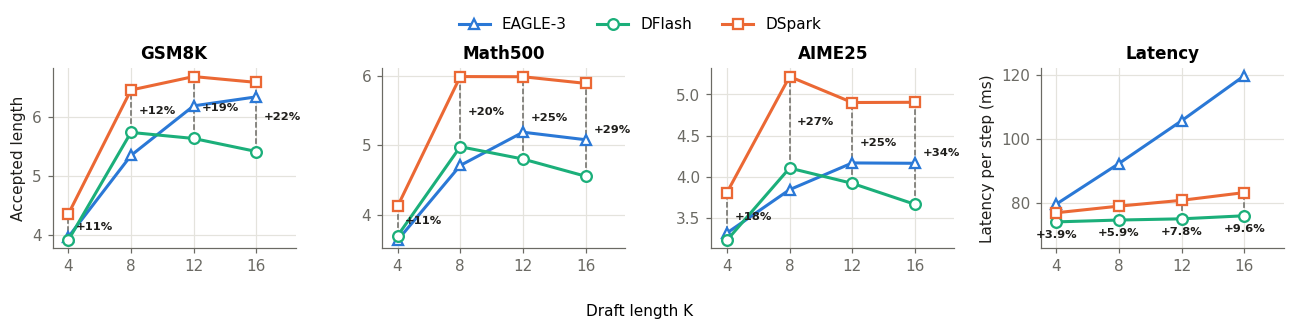

In [8]:
def annotate_gap(ax, k, y_top, y_ref, pct, fmt, fontsize=7.5, below=False):
    # Dashed connector behind the markers (lines and markers are drawn at zorder 2).
    ax.plot([k, k], [y_ref, y_top], ls="--", color=MUTED, lw=1, zorder=1.5)
    if below:  # gap too small for a side label: put it under the lower point
        xy, offset, ha, va = (k, min(y_top, y_ref)), (0, -5), "center", "top"
    else:
        xy, offset, ha, va = (k, (y_top + y_ref) / 2), (5, 0), "left", "center"
    ax.annotate(fmt.format(pct), xy=xy, xytext=offset, textcoords="offset points",
                fontsize=fontsize, color=INK, ha=ha, va=va, fontweight="bold")


def draw_vs_k(ax, value, ks, annotate=None, annotate_size=7.5):
    """One line per method of value(method, k); optional focus-vs-reference gap labels."""
    for m in MS:
        ax.plot(ks, [value(m, k) for k in ks], **STYLE[m], markerfacecolor="white",
                markeredgewidth=plt.rcParams["lines.linewidth"] * 0.75)
    if annotate and FOCUS_METHOD in MS and REF_METHOD in MS:
        pairs = {k: (value(FOCUS_METHOD, k), value(REF_METHOD, k)) for k in ks}
        pairs = {k: ab for k, ab in pairs.items() if np.all(np.isfinite(ab))}
        lo, hi = ax.get_ylim()
        below = bool(pairs) and max(abs(a - b) for a, b in pairs.values()) < 0.15 * (hi - lo)
        if below:
            ax.set_ylim(lo - 0.12 * (hi - lo), hi)  # room for the labels under the lines
        for k, (a, b) in pairs.items():
            annotate_gap(ax, k, a, b, rel(a, b), annotate, annotate_size, below)
    ax.set_xticks(ks)
    ax.set_xlim(min(ks) - 1, max(ks) + 2.5)  # room for the labels right of the last K


def method_handles(methods, ar=False):
    handles = [plt.Line2D([], [], color=STYLE[m]["color"], marker=STYLE[m]["marker"], markerfacecolor="white",
                          markeredgewidth=1.5, label=name(m)) for m in methods]
    if ar:
        handles.append(plt.Line2D([], [], color=AR_COLOR, ls="--", lw=1.2, label=name(AR_METHOD)))
    return handles


KF = [k for k in K_FIG2 if k in KS]

ncols = len(DS) + int(STEP_TIMING)
fig, axes = plt.subplots(1, ncols, figsize=(3.0 * ncols, 2.9), squeeze=False)
for ax, d in zip(axes[0], DS):
    draw_vs_k(ax, lambda m, k: metric(m, d, k, "accept_len"), KF, annotate="{:+.0f}%")
    ax.set_title(dname(d))
axes[0, 0].set_ylabel("Accepted length")
if STEP_TIMING:
    ax = axes[0, -1]
    draw_vs_k(ax, lambda m, k: macro(m, k, "ms_per_step_total"), KF, annotate="{:+.1f}%")
    ax.set_title("Latency")
    ax.set_ylabel("Latency per step (ms)")
fig.legend(handles=method_handles(MS), loc="upper center", ncol=len(MS), bbox_to_anchor=(0.5, 1.0))
fig.supxlabel("Draft length K", fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.92))
save(fig, "fig2_accept_len_latency_vs_k")
plt.show()


### Figure 2b — Decode latency per token vs `K`

**Per token** = decode ms / Σ (generated_len − 1): what the user sees; combines the round cost with accepted
length. Decode = `draft + verification + update + commit`; target prefill and `init_context` are **excluded**
(§11 reports them separately). One panel for `K` in `K_FIG2`: unweighted mean of the per-dataset values over the three
datasets (the AR baseline is in Table §11.2). Latency on our benchmark prompts with their natural context
lengths (no controlled averaging over fixed context lengths as in the DSpark paper).

Caveat: at temperature > 0 each method generates its own continuation, so context lengths (and thus per-round
target cost) differ somewhat between methods; compare `generated_len` in §11.


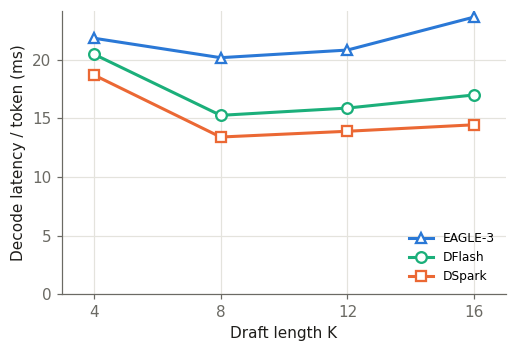

**Supporting table for Figure 2.** Δ columns are relative to DFlash at the same K.

In [9]:
if STEP_TIMING:
    fig, ax = plt.subplots(figsize=(4.8, 3.3))
    draw_vs_k(ax, lambda m, k: macro(m, k, "ms_per_token"), KF)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Draft length K")
    ax.set_ylabel("Decode latency / token (ms)")
    ax.set_xlim(min(KF) - 1, max(KF) + 1)
    ax.legend(handles=method_handles(MS), fontsize=8, loc="lower right")
    fig.tight_layout()
    save(fig, "fig2b_latency_per_token_vs_k")
    plt.show()

rows = []
for d in DS:
    for m in MS:
        for k in KS:
            a, b = metric(m, d, k, "accept_len"), metric(REF_METHOD, d, k, "accept_len")
            lr, lr_ref = metric(m, d, k, "ms_per_round"), metric(REF_METHOD, d, k, "ms_per_round")
            ls, ls_ref = metric(m, d, k, "ms_per_step_total"), metric(REF_METHOD, d, k, "ms_per_step_total")
            lt, lt_ref = metric(m, d, k, "ms_per_token"), metric(REF_METHOD, d, k, "ms_per_token")
            rows.append({"dataset": dname(d), "method": name(m), "K": k, "accept. len": a,
                         "ms / round": lr, "ms / step (total)": ls, "ms / token": lt, "speedup vs AR": metric(m, d, k, "speedup"),
                         f"Δ accept. len vs {name(REF_METHOD)}": rel(a, b),
                         f"Δ ms/round vs {name(REF_METHOD)}": rel(lr, lr_ref),
                         f"Δ ms/step (total) vs {name(REF_METHOD)}": rel(ls, ls_ref),
                         f"Δ ms/token vs {name(REF_METHOD)}": rel(lt, lt_ref)})
T2 = pd.DataFrame(rows).set_index(["dataset", "method", "K"])
display(Markdown(f"**Supporting table for Figure 2.** Δ columns are relative to {name(REF_METHOD)} at the same K."))
display(T2.style.format({c: ("{:+.1f}%" if c.startswith("Δ") else "{:.2f}") for c in T2.columns}, na_rep="—"))
save_table(T2, "table_fig2_support")

## 9. Figure 3 — Decode latency breakdown (`K = BASE_K`) and additional memory vs `K`

Saved twice: `fig3_latency_breakdown_memory` is 2 × 1 at single-column width (3.4 in, fonts at printed size;
breakdown on top, memory below); `fig3_latency_breakdown_memory_wide` is the 1 × 2 layout for a full-width figure.

**Left: latency breakdown.** Decode ms per generated token at `K = BASE_K`, split into the four decode phases
(draft, verification, drafter update; in the plot `commit / other` is folded into the drafter-update segment).
The phases tile the decode timeline, so a stack sums to the decode ms/token of Figure 2b. Unweighted mean of the per-dataset values over the three datasets; AR is not shown
(its decode is target verification only, see §11.2 for the numbers).

**Right: additional memory over AR** for `K` in `K_FIG2`, unweighted mean of the per-dataset values over the three datasets.

**Definition.** The logs record absolute `max_memory_allocated()` (weights included) per sample, separately for
prefill + `init_context` and for decode. Per sample, `peak = max(prefill_peak, decode_peak)`. The additional memory
of a method is the **paired** difference to the AR baseline on the same prompt (`dataset`, `sample_idx`; identical
`prompt_sha1`):

$$\Delta M = \operatorname{mean}_{\text{samples}}\big(\text{peak}_{\text{method}} - \text{peak}_{\text{AR}}\big).$$

Both runs share the target weights, the target KV cache and the target activations, so the difference isolates what
speculative decoding adds. It is split into

* **drafter weights** — `post_load_allocated_bytes` (method) − (AR), from `workers/*.json`: the drafter's parameters
  as actually allocated (including its own embedding / LM-head copies);
* **runtime** — the rest: drafter KV cache / context features, drafter activations, and the wider (K+1-token)
  target verification forward (logits, probabilities, hidden states).

Why not `decode_peak − prefill_peak`: both are absolute peaks of different phases; their difference mixes the
target KV growth during generation with the drafter and says nothing about drafter weights, which are resident in
both. Caveat: at temperature > 0 a method's output length differs from AR's on the same prompt, so the target KV
cache differs too; the mean context-length difference is reported with the bars (≈ 0.14 MiB of bf16 KV per token for
Qwen3-4B, before `DynamicCache` growth overheads).

/tmp/ipykernel_858525/2158669871.py:9: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = grp.set_index(key)[["peak_bytes", "context_len"]].join(ar, rsuffix="_ar", how="inner")
/tmp/ipykernel_858525/2158669871.py:9: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = grp.set_index(key)[["peak_bytes", "context_len"]].join(ar, rsuffix="_ar", how="inner")
/tmp/ipykernel_858525/2158669871.py:9: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = grp.set_index(key)[["peak_bytes", "context_len"]].join(ar, rsuffix="_ar", how="inner")
/tmp/ipykernel_858525/2158669871.py:9: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are d

/tmp/ipykernel_858525/2158669871.py:9: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = grp.set_index(key)[["peak_bytes", "context_len"]].join(ar, rsuffix="_ar", how="inner")
/tmp/ipykernel_858525/2158669871.py:9: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = grp.set_index(key)[["peak_bytes", "context_len"]].join(ar, rsuffix="_ar", how="inner")
/tmp/ipykernel_858525/2158669871.py:9: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = grp.set_index(key)[["peak_bytes", "context_len"]].join(ar, rsuffix="_ar", how="inner")
/tmp/ipykernel_858525/2158669871.py:9: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are d

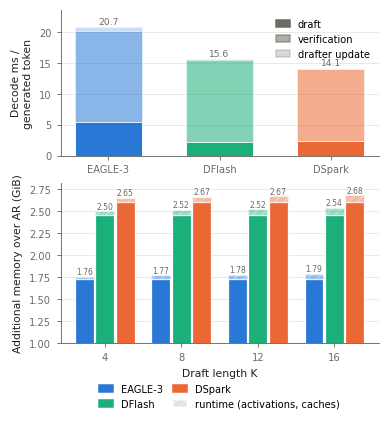

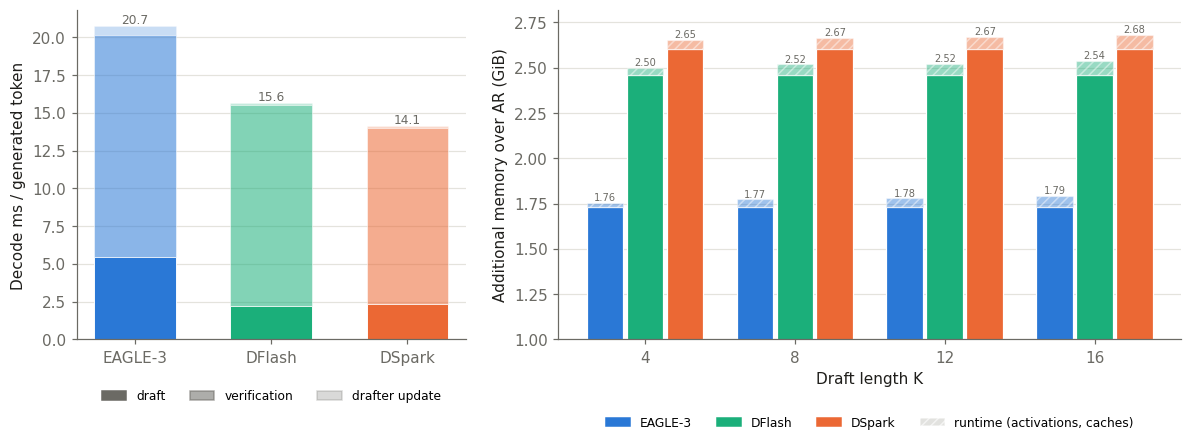

In [10]:
def memory_overhead() -> pd.DataFrame:
    if not HAS_AR:
        return pd.DataFrame()
    key = ["dataset", "sample_idx"]
    ar = samples[samples["method"] == AR_METHOD].set_index(key)[["peak_bytes", "context_len"]]
    post = workers.groupby("method")["post_load_allocated_bytes"].max() if len(workers) else pd.Series(dtype=float)
    rows = []
    for (m, d, k), grp in samples[samples["method"].isin(MS)].groupby(GROUP):
        j = grp.set_index(key)[["peak_bytes", "context_len"]].join(ar, rsuffix="_ar", how="inner")
        if not len(j):
            continue
        total = (j["peak_bytes"] - j["peak_bytes_ar"]).mean() / GIB
        weights = (post.get(m, np.nan) - post.get(AR_METHOD, np.nan)) / GIB
        rows.append({"method": m, "dataset": d, "k": k, "paired_samples": len(j), "total_gib": total,
                     "weights_gib": weights, "runtime_gib": total - weights,
                     "peak_gib": j["peak_bytes"].mean() / GIB, "ar_peak_gib": j["peak_bytes_ar"].mean() / GIB,
                     "context_len_diff": (j["context_len"] - j["context_len_ar"]).mean()})
    return pd.DataFrame(rows)


MEM = memory_overhead()


PHASE_SHADES = {"draft_ms": 1.0, "verification_ms": 0.55, "update_ms": 0.25}
# Plotted phases: commit / other is folded into the drafter-update segment.
PLOT_PHASES = {"draft_ms": ["draft_ms"], "verification_ms": ["verification_ms"], "update_ms": ["update_ms", "commit_ms"]}


def plot_breakdown(ax, k, label_size=8):
    for i, m in enumerate(MS):
        bottom = 0.0
        for p, parts in PLOT_PHASES.items():
            v = sum(macro(m, k, q + "_per_token") for q in parts)
            v = 0 if not np.isfinite(v) else v
            ax.bar(i, v, 0.6, bottom=bottom, color=STYLE[m]["color"], alpha=PHASE_SHADES[p],
                   edgecolor="white", linewidth=0.6)
            bottom += v
        ax.annotate(f"{bottom:.1f}", (i, bottom), xytext=(0, 2), textcoords="offset points",
                    ha="center", fontsize=label_size, color=MUTED)
    ax.set_xticks(range(len(MS)), [name(m) for m in MS])
    ax.set_ylabel("Decode ms / generated token")
    ax.grid(axis="x", visible=False)
    return [plt.Rectangle((0, 0), 1, 1, color=MUTED, alpha=a, label=PHASE_NAMES[p]) for p, a in PHASE_SHADES.items()]


def plot_memory(ax, mem: pd.DataFrame, label_size=6.5):
    avg = mem.groupby(["method", "k"])[["total_gib", "weights_gib", "runtime_gib"]].mean()
    width = 0.8 / max(len(MS), 1)
    x = np.arange(len(KF))
    for i, m in enumerate(MS):
        sub = avg.loc[m].reindex(KF) if m in avg.index.get_level_values(0) else avg.iloc[:0].reindex(KF)
        xs = x - 0.4 + width * (i + 0.5)
        c = STYLE[m]["color"]
        w, r = sub["weights_gib"].to_numpy(), sub["runtime_gib"].to_numpy()
        if np.isfinite(w).any():
            ax.bar(xs, w, width * 0.92, color=c, edgecolor="white", linewidth=0.8)
            ax.bar(xs, r, width * 0.92, bottom=w, color=c, alpha=0.45, hatch="////", edgecolor="white", linewidth=0.8)
        else:
            ax.bar(xs, sub["total_gib"], width * 0.92, color=c, edgecolor="white", linewidth=0.8)
        for xi, t in zip(xs, sub["total_gib"]):
            if np.isfinite(t):
                ax.annotate(f"{t:.2f}", (xi, t), xytext=(0, 1.5), textcoords="offset points",
                            ha="center", fontsize=label_size, color=MUTED)
    ax.set_xticks(x, [str(k) for k in KF])
    ax.set_xlabel("Draft length K")
    ax.set_ylabel("Additional memory over AR (GiB)")
    ax.set_ylim(bottom=1)  # truncated axis: bar heights are not proportional to the values
    ax.grid(axis="x", visible=False)
    handles = [plt.Rectangle((0, 0), 1, 1, color=STYLE[m]["color"], label=name(m)) for m in MS]
    handles += [plt.Rectangle((0, 0), 1, 1, facecolor="#cfcfca", alpha=0.6, hatch="////", edgecolor="white",
                              label="runtime (activations, caches)")]
    return handles


# Two versions: "column" (2 x 1, one column of a two-column paper, drawn at its printed width of 3.4 in so the
# fonts are in true points) and "wide" (1 x 2, full text width / figure*).
COLUMN_RC = {"font.size": 7, "axes.labelsize": 7, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5,
             "legend.fontsize": 6.5, "axes.linewidth": 0.6, "grid.linewidth": 0.5, "hatch.linewidth": 0.6,
             "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5}


def plot_fig3(layout, fname):
    column = layout == "column"
    with plt.rc_context(COLUMN_RC if column else {}):
        if column:
            fig, axes = plt.subplots(2, 1, figsize=(3.4, 3.7), gridspec_kw={"height_ratios": [1, 1.1]})
        else:
            fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
        if STEP_TIMING:
            handles = plot_breakdown(axes[0], BASE_K, label_size=6 if column else 8)
            if column:  # three bars: the phase legend fits in the empty top-right corner
                axes[0].set_ylim(top=axes[0].get_ylim()[1] * 1.08)
                axes[0].legend(handles=handles, loc="upper right", handlelength=1.4)
                axes[0].set_ylabel("Decode ms /\ngenerated token")  # one line is taller than the panel
            else:
                axes[0].legend(handles=handles, loc="upper center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.12))
        else:
            axes[0].set_axis_off()
        if len(MEM):
            handles = plot_memory(axes[1], MEM, label_size=5 if column else 6.5)
            if column:
                axes[1].legend(handles=handles, loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.2),
                               handlelength=1.4, columnspacing=1.0)
            else:
                axes[1].legend(handles=handles, loc="upper center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.2))
        else:
            axes[1].set_axis_off()
        fig.tight_layout(pad=0.3 if column else 1.08, h_pad=0.8 if column else None)
        save(fig, fname)
        plt.show()


if STEP_TIMING or len(MEM):
    plot_fig3("column", "fig3_latency_breakdown_memory")
    plot_fig3("wide", "fig3_latency_breakdown_memory_wide")

if len(MEM):
    T3 = MEM.assign(method=MEM["method"].map(name), dataset=MEM["dataset"].map(dname)) \
            .set_index(["dataset", "method", "k"]).sort_index()
    display(T3.style.format({"total_gib": "{:.3f}", "weights_gib": "{:.3f}", "runtime_gib": "{:.3f}",
                             "peak_gib": "{:.2f}", "ar_peak_gib": "{:.2f}", "context_len_diff": "{:+.0f}"}))
    save_table(T3, "table_fig3_memory")
else:
    print("no AR baseline in the logs: additional memory cannot be computed")


## 10. Table 4 — GSM8K comparison with the EAGLE-3 paper

**Special metric for this table only.** To match the EAGLE-3 paper's *average acceptance length* τ
(tokens generated per drafting–verification cycle):

$$\tau = \frac{\sum \text{generated\_len}}{\sum \text{num\_steps}}.$$

`generated_len` includes the one token sampled at prefill and is trimmed at `max_new_tokens`, so τ differs slightly
from the native `A` of Table 1 (it is ≈ 1 + 1/steps for AR). It is **not** used anywhere else in the notebook.

Speedup = AR decode ms/token ÷ method decode ms/token on the same prompts (decode only, as everywhere in this
report; the EAGLE-3 paper reports end-to-end speedups, so the comparison is indicative). For each speculative
method, the K with the best `TABLE4_SELECT_BY` among `K_VALUES` is shown; all candidates are listed below.
Rows marked *paper* are copied from `EAGLE3_PAPER_GSM8K` in the configuration cell, not measured.

In [11]:
d4 = TABLE4_DATASET
cand = G[(G["dataset"] == d4) & G["method"].isin(MS)].copy()
sel_col = {"speedup": "speedup", "tau": "tau_eagle"}[TABLE4_SELECT_BY]
rows = []
if HAS_AR and (G["dataset"] == d4).any():
    rows.append({"Source": "ours", "Method": name(AR_METHOD), "K": "—",
                 "Average Acceptance Length (τ)": metric(AR_METHOD, d4, 0, "tau_eagle"), "Speedup vs AR": 1.0})
for m in MS:
    c = cand[cand["method"] == m].dropna(subset=[sel_col])
    if len(c):
        best = c.loc[c[sel_col].idxmax()]
        rows.append({"Source": "ours", "Method": name(m), "K": int(best["k"]),
                     "Average Acceptance Length (τ)": best["tau_eagle"], "Speedup vs AR": best["speedup"]})
p = EAGLE3_PAPER_GSM8K
label = "EAGLE-3 (paper" + (f", {p['target_model']}" if p.get("target_model") else "") + \
        (f", T={p['temperature']}" if p.get("temperature") is not None else "") + ")"
rows.append({"Source": "paper", "Method": label, "K": "—",
             "Average Acceptance Length (τ)": p.get("acceptance_length"), "Speedup vs AR": p.get("speedup")})
T4 = pd.DataFrame(rows).set_index(["Source", "Method"])
T4 = T4.astype({"Average Acceptance Length (τ)": float, "Speedup vs AR": float})
display(Markdown(f"**Table 4.** {dname(d4)}, Qwen3-4B. K selected by best {TABLE4_SELECT_BY}; "
                 f"τ = Σ generated_len / Σ num_steps."))
display(T4.style.format({"Average Acceptance Length (τ)": "{:.2f}", "Speedup vs AR": "{:.2f}×"}, na_rep="—"))
save_table(T4, f"table4_{d4}_eagle3_compat")
if p.get("acceptance_length") is None:
    print("EAGLE3_PAPER_GSM8K is a placeholder: fill it in from the EAGLE-3 paper (with its target model and temperature).")

display(Markdown("All candidates:"))
display(cand.assign(method=cand["method"].map(name)).set_index(["method", "k"])[
    ["tau_eagle", "accept_len", "ms_per_token", "speedup"]].sort_index())

**Table 4.** GSM8K, Qwen3-4B. K selected by best speedup; τ = Σ generated_len / Σ num_steps.

EAGLE3_PAPER_GSM8K is a placeholder: fill it in from the EAGLE-3 paper (with its target model and temperature).


All candidates:

tau_eagle  accept_len  ms_per_token  speedup
method  k                                               
DFlash  4       3.928       3.915        18.792    3.070
        7       5.407       5.390        13.727    4.203
        8       5.754       5.735        12.934    4.461
        12      5.652       5.633        13.248    4.355
        16      5.431       5.413        13.984    4.126
DSpark  4       4.368       4.355        17.554    3.287
        7       5.947       5.930        13.148    4.388
        8       6.470       6.450        12.162    4.744
        12      6.699       6.678        12.041    4.792
        16      6.601       6.579        12.586    4.584
EAGLE-3 4       3.981       3.968        19.894    2.900
        7       5.018       5.002        18.203    3.170
        8       5.363       5.346        17.148    3.365
        12      6.203       6.184        16.975    3.399
        16      6.356       6.335        18.774    3.073

## 11. Supporting diagnostics

### 11.1 Draft length, acceptance and progress per round

`eff. draft len` vs `K` shows how often proposals are shorter than requested (EAGLE-3 chain stopped at a stop token;
truncation after an accepted stop token). `accepted / round` excludes the bonus token; `accept. len` (= committed /
round) includes it. `accept. rate` = Σ committed / (Σ effective + rounds) (bonus included, DeepSpec's `verify_rate`);
`draft accept. rate` = Σ accepted / Σ effective (bonus excluded).

In [12]:
DIAG = G[G["method"].isin(MS + [AR_METHOD])].assign(
    method=lambda x: pd.Categorical(x["method"].map(name), [name(m) for m in [AR_METHOD] + MS]),
    dataset=lambda x: pd.Categorical(x["dataset"].map(dname), [dname(d) for d in DS]))
D1 = DIAG.set_index(["dataset", "method", "k"]).sort_index()[
    ["eff_draft_len", "accepted_draft_per_step", "accept_len", "acceptance_rate", "draft_acceptance_rate",
     "steps", "n_samples"]].rename(columns={
        "eff_draft_len": "eff. draft len", "accepted_draft_per_step": "accepted / round",
        "accept_len": "accept. len", "acceptance_rate": "accept. rate", "draft_acceptance_rate": "draft accept. rate",
        "steps": "rounds", "n_samples": "samples"})
display(D1.style.format({"eff. draft len": "{:.2f}", "accepted / round": "{:.2f}", "accept. len": "{:.2f}",
                         "accept. rate": "{:.3f}", "draft accept. rate": "{:.3f}"}, na_rep="—"))
save_table(D1, "diag_acceptance")

### 11.2 Decode latency breakdown

Per round, per dataset, all `K`, AR included. The plot at `K = BASE_K` (mean over datasets) is Figure 3, left.
`commit / other` = KV crop, token commit, stop-token check and loop bookkeeping.


In [13]:
if STEP_TIMING:
    D2 = DIAG.set_index(["dataset", "method", "k"]).sort_index()[
        [p + "_per_round" for p in PHASES] + ["ms_per_round", "ms_per_token", "tokens_per_s", "speedup"]]
    D2.columns = [f"{PHASE_NAMES[p]} ms/round" for p in PHASES] + ["ms/round", "ms/token", "tokens/s", "speedup"]
    display(D2.style.format("{:.2f}", na_rep="—"))
    save_table(D2, "diag_latency")

### 11.3 Prefill, drafter initialisation, lengths and memory

Mean per sample. Prefill and `init_context` are excluded from all decode metrics above; they are reported here so
that the excluded cost is visible. `length-limited` = share of samples that hit `max_new_tokens`.

In [14]:
D3 = DIAG.set_index(["dataset", "method", "k"]).sort_index()[
    ["prefill_ms", "init_context_ms", "prompt_len", "generated_len", "length_limited", "steps", "peak_gib", "peak_max_gib"]
].rename(columns={"prefill_ms": "target prefill ms", "init_context_ms": "init_context ms", "prompt_len": "prompt len",
                  "generated_len": "generated len", "length_limited": "length-limited", "steps": "rounds",
                  "peak_gib": "peak GiB (mean)", "peak_max_gib": "peak GiB (max)"})
display(D3.style.format({"target prefill ms": "{:.1f}", "init_context ms": "{:.2f}", "prompt len": "{:.0f}",
                         "generated len": "{:.0f}", "length-limited": "{:.0%}", "peak GiB (mean)": "{:.2f}",
                         "peak GiB (max)": "{:.2f}"}, na_rep="—"))
save_table(D3, "diag_prefill_lengths_memory")

if len(workers):
    W = workers.groupby("method").agg(draft_params=("draft_params", "max"),
                                      post_load_gib=("post_load_allocated_bytes", lambda x: x.max() / GIB))
    W = W.reindex([m for m in [AR_METHOD] + MS if m in W.index])
    W["drafter params (M)"] = W.pop("draft_params") / 1e6
    W.index = W.index.map(name)
    display(Markdown("Drafter size (all drafter parameters, incl. its own embedding / LM head) and memory after loading:"))
    display(W.style.format({"post_load_gib": "{:.2f}", "drafter params (M)": "{:.0f}"}, na_rep="—"))

Drafter size (all drafter parameters, incl. its own embedding / LM head) and memory after loading:

,post_load_gib,drafter params (M)
method,,
AR (Qwen3-4B),7.55,—
EAGLE-3,9.27,927
DFlash,10.00,1315
DSpark,10.15,1393


### 11.4 Peak VRAM vs context length, and speedup vs additional VRAM

Left: per-sample peak allocated memory against final context length (prompt + generated) at `BASE_K`, with the AR
baseline. Right: decode speedup vs additional memory (Figure 3 definition), one point per (method, K), averaged over
datasets.

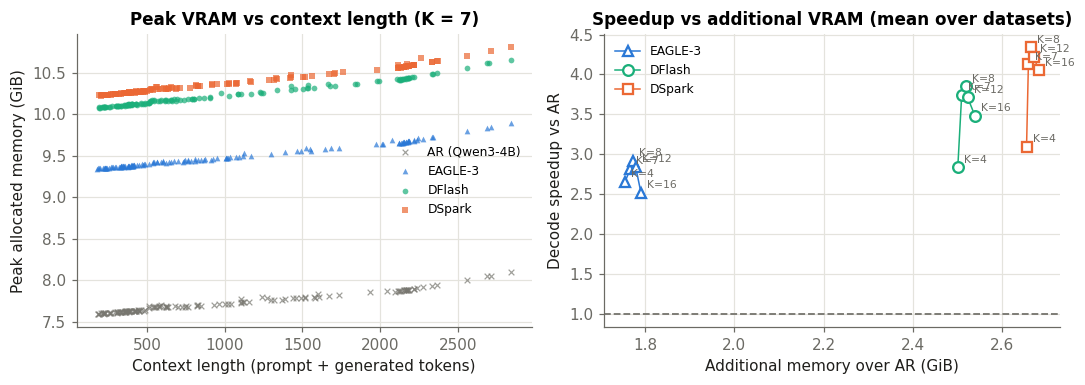

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
for m in ([AR_METHOD] if HAS_AR else []) + MS:
    sub = samples[(samples["method"] == m) & (samples["k"] == (0 if m == AR_METHOD else BASE_K))]
    if len(sub):
        ax.scatter(sub["context_len"], sub["peak_bytes"] / GIB, s=14, alpha=0.7, color=STYLE[m]["color"],
                   marker=STYLE[m]["marker"], label=name(m), linewidths=0.8 if STYLE[m]["marker"] == "x" else 0)
ax.set_xlabel("Context length (prompt + generated tokens)")
ax.set_ylabel("Peak allocated memory (GiB)")
ax.set_title(f"Peak VRAM vs context length (K = {BASE_K})")
ax.legend(fontsize=8)

ax = axes[1]
if len(MEM):
    sp = G[G["method"].isin(MS)].groupby(["method", "k"])["speedup"].mean()
    mm = MEM.groupby(["method", "k"])["total_gib"].mean()
    for m in MS:
        ks = [k for k in KS if (m, k) in sp.index and (m, k) in mm.index]
        ax.plot([mm[(m, k)] for k in ks], [sp[(m, k)] for k in ks], **STYLE[m], ls="-", lw=1,
                markerfacecolor="white", markeredgewidth=1.5, label=name(m))
        for k in ks:
            ax.annotate(f"K={k}", (mm[(m, k)], sp[(m, k)]), xytext=(4, 3), textcoords="offset points",
                        fontsize=7, color=MUTED)
    ax.axhline(1, color=AR_COLOR, ls="--", lw=1.2)
    ax.set_xlabel("Additional memory over AR (GiB)")
    ax.set_ylabel("Decode speedup vs AR")
    ax.set_title("Speedup vs additional VRAM (mean over datasets)")
    ax.legend(fontsize=8)
fig.tight_layout()
save(fig, "diag_memory_context_speedup")
plt.show()

### 11.5 Conditional acceptance vs prefix survival, all K

Solid: conditional acceptance (Figure 1 definition). Dashed: DeepSpec's `accept_rates_by_position` (prefix survival
`P(accepted ≥ i | effective_len ≥ i)`), which is the product of the conditionals and therefore always decays. Rows =
datasets, columns = `K`; shows how running the block-7 checkpoints at other `K` changes per-position acceptance.

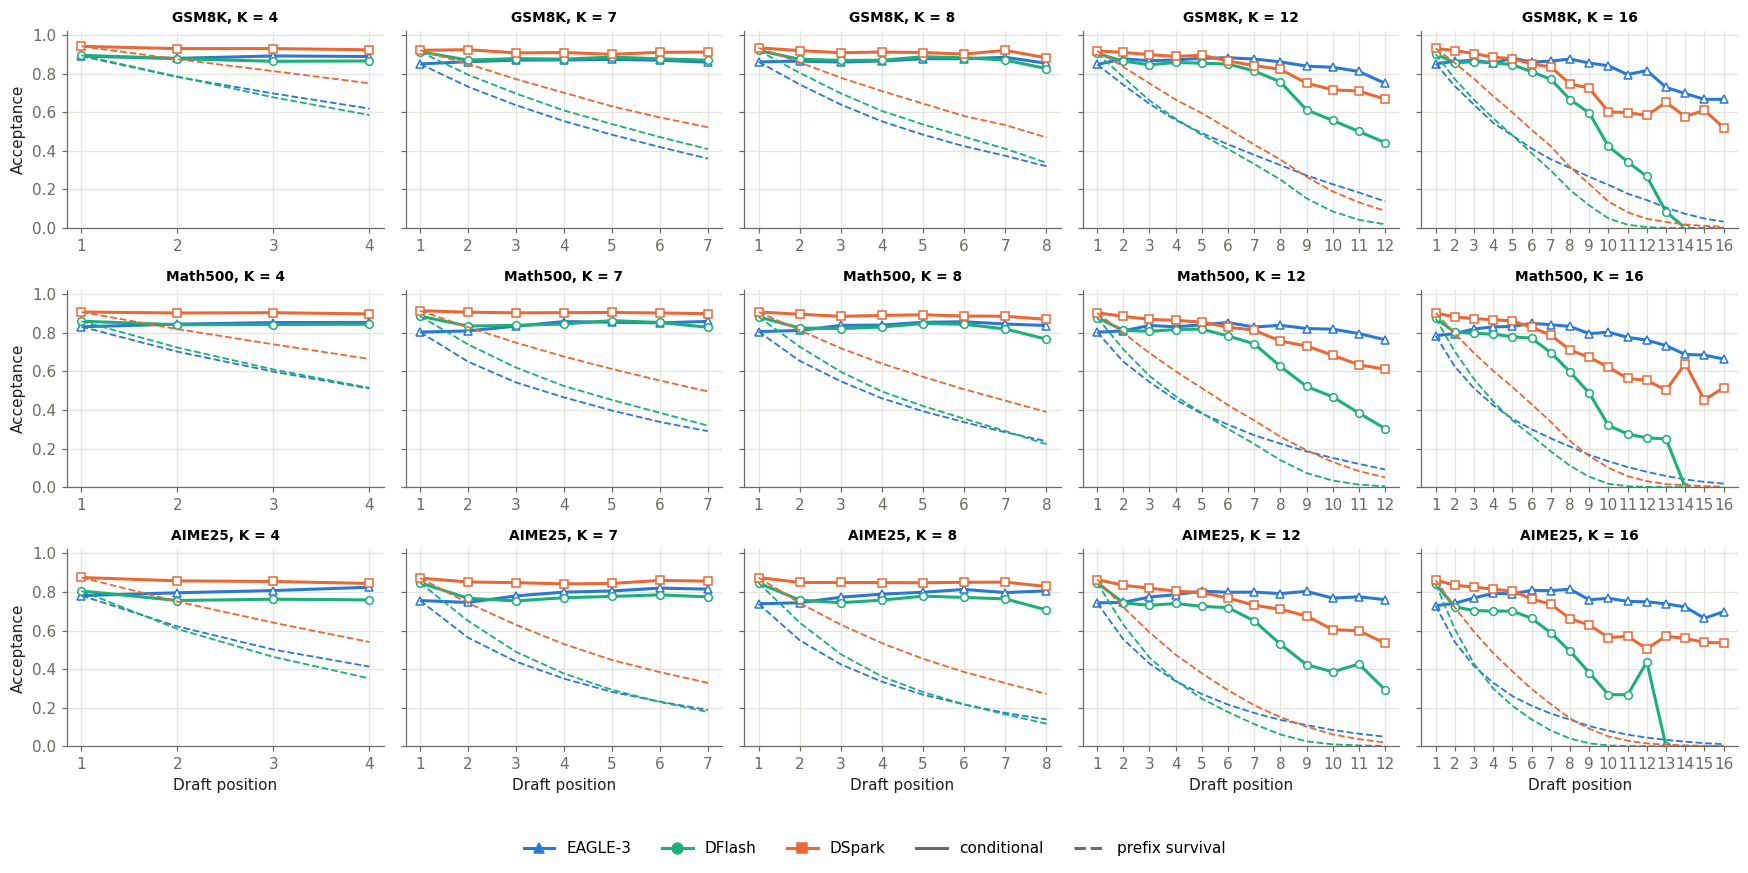

In [16]:
fig, axes = plt.subplots(len(DS), len(KS), figsize=(3.2 * len(KS), 2.6 * len(DS)), sharey=True, squeeze=False)
for i, d in enumerate(DS):
    for j, k in enumerate(KS):
        ax = axes[i, j]
        for m in MS:
            p = POS[(m, d, k)]
            ax.plot(p["position"], p["conditional"], **STYLE[m], markersize=5, markerfacecolor="white")
            ax.plot(p["position"], p["survival"], color=STYLE[m]["color"], ls="--", lw=1.2)
        ax.set_xticks(range(1, k + 1))
        ax.set_ylim(0, 1.02)
        ax.set_title(f"{dname(d)}, K = {k}", fontsize=9)
        if i == len(DS) - 1:
            ax.set_xlabel("Draft position")
    axes[i, 0].set_ylabel("Acceptance")
legend_below(fig, MS, extra=[plt.Line2D([], [], color=MUTED, ls="-", label="conditional"),
                              plt.Line2D([], [], color=MUTED, ls="--", label="prefix survival")])
fig.tight_layout(rect=(0, 0.05, 1, 1))
save(fig, "diag_position_acceptance_all_k")
plt.show()

## 12. Main Results

Accepted length at `K = BASE_K` (the released checkpoints' trained draft length), in the layout of the paper's
math table. **A = Σ committed / Σ rounds**, i.e. it **includes the bonus / corrected token** emitted by the target
on every verification round (same definition as the DSpark paper table and Table 1). Best value per column is bold.

In [17]:
# ---- acceptance len data ------------------------------------------------------------------------
ML_K = BASE_K
ML = pd.DataFrame({dname(d): [metric(m, d, ML_K, "accept_len") for m in MS] for d in DS},
                  index=[name(m) for m in MS])
ML.index.name = "Drafter"
display(Markdown(f"**Main Results.** Accepted length (incl. bonus token), Qwen3-4B target, K = {ML_K}."))
display(ML.style.apply(bold_max).format("{:.2f}", na_rep="—"))
save_table(ML, f"main_results_accept_len_K{ML_K}")


def latex_cell(v, best):
    if not np.isfinite(v):
        return "--"
    return rf"\textbf{{{v:.2f}}}" if v == best else f"{v:.2f}"


best = ML.max(axis=0)
body = "\n".join("\t\t" + " & ".join([idx] + [latex_cell(ML.loc[idx, c], best[c]) for c in ML.columns]) + r" \\"
                 for idx in ML.index)
n = len(ML.columns)
print(rf"""\begin{{table}}[t]
	\centering
	\caption{{Accepted length for different drafters on math benchmarks.}}
	\label{{tab:math_results}}
	\begin{{tabular}}{{l{"c" * n}}}
		\toprule
		\multirow{{2}}{{*}}{{Drafter}} & \multicolumn{{{n}}}{{c}}{{Math}} \\
		\cmidrule(lr){{2-{n + 1}}}
		& {" & ".join(ML.columns)} \\
		\midrule
{body}
		\bottomrule
	\end{{tabular}}
\end{{table}}""")

**Main Results.** Accepted length (incl. bonus token), Qwen3-4B target, K = 7.

,GSM8K,Math500,AIME25
Drafter,,,
EAGLE-3,5.00,4.48,3.81
DFlash,5.39,4.91,4.06
DSpark,5.93,5.82,4.93


\begin{table}[t]
	\centering
	\caption{Accepted length for different drafters on math benchmarks.}
	\label{tab:math_results}
	\begin{tabular}{lccc}
		\toprule
		\multirow{2}{*}{Drafter} & \multicolumn{3}{c}{Math} \\
		\cmidrule(lr){2-4}
		& GSM8K & Math500 & AIME25 \\
		\midrule
		EAGLE-3 & 5.00 & 4.48 & 3.81 \\
		DFlash & 5.39 & 4.91 & 4.06 \\
		DSpark & \textbf{5.93} & \textbf{5.82} & \textbf{4.93} \\
		\bottomrule
	\end{tabular}
\end{table}


### 12.1 Appendix — accepted length for the other draft lengths

Same metric and layout as above (incl. bonus token), for every logged `K ≠ BASE_K`; the best value per column is
bold within each `K` block. `K < 7` runs below and `K > 7` above the checkpoints' trained draft length.

In [18]:
# ---- acceptance len data, appendix (K != BASE_K) -------------------------------------------------
APPENDIX_K = [k for k in KS if k != BASE_K]
MLA = pd.concat({k: pd.DataFrame({dname(d): [metric(m, d, k, "accept_len") for m in MS] for d in DS},
                                 index=[name(m) for m in MS]) for k in APPENDIX_K}, names=["K", "Drafter"])
display(Markdown(f"**Appendix.** Accepted length (incl. bonus token), Qwen3-4B target, K = {APPENDIX_K}."))
display(MLA.style.apply(lambda col: [s for k in APPENDIX_K for s in bold_max(col.loc[k])]).format("{:.2f}", na_rep="—"))
save_table(MLA, "appendix_accept_len_by_K")

n = len(MLA.columns)
blocks = []
for k in APPENDIX_K:
    t = MLA.loc[k]
    best = t.max(axis=0)
    rows = [" & ".join([rf"\multirow{{{len(t)}}}{{*}}{{{k}}}" if i == 0 else ""] + [idx]
                       + [latex_cell(t.loc[idx, c], best[c]) for c in t.columns]) + r" \\"
            for i, idx in enumerate(t.index)]
    blocks.append("\n".join("\t\t" + r for r in rows))
body = "\n\t\t\\midrule\n".join(blocks)
print(rf"""\begin{{table}}[t]
	\centering
	\caption{{Accepted length for different drafters on math benchmarks at draft lengths $K \in \{{{", ".join(map(str, APPENDIX_K))}\}}$ (incl. bonus token).}}
	\label{{tab:math_results_by_k}}
	\begin{{tabular}}{{cl{"c" * n}}}
		\toprule
		\multirow{{2}}{{*}}{{$K$}} & \multirow{{2}}{{*}}{{Drafter}} & \multicolumn{{{n}}}{{c}}{{Math}} \\
		\cmidrule(lr){{3-{n + 2}}}
		& & {" & ".join(MLA.columns)} \\
		\midrule
{body}
		\bottomrule
	\end{{tabular}}
\end{{table}}""")

**Appendix.** Accepted length (incl. bonus token), Qwen3-4B target, K = [4, 8, 12, 16].

\begin{table}[t]
	\centering
	\caption{Accepted length for different drafters on math benchmarks at draft lengths $K \in \{4, 8, 12, 16\}$ (incl. bonus token).}
	\label{tab:math_results_by_k}
	\begin{tabular}{clccc}
		\toprule
		\multirow{2}{*}{$K$} & \multirow{2}{*}{Drafter} & \multicolumn{3}{c}{Math} \\
		\cmidrule(lr){3-5}
		& & GSM8K & Math500 & AIME25 \\
		\midrule
		\multirow{3}{*}{4} & EAGLE-3 & 3.97 & 3.64 & 3.32 \\
		 & DFlash & 3.92 & 3.70 & 3.23 \\
		 & DSpark & \textbf{4.36} & \textbf{4.12} & \textbf{3.81} \\
		\midrule
		\multirow{3}{*}{8} & EAGLE-3 & 5.35 & 4.71 & 3.84 \\
		 & DFlash & 5.74 & 4.98 & 4.10 \\
		 & DSpark & \textbf{6.45} & \textbf{5.99} & \textbf{5.22} \\
		\midrule
		\multirow{3}{*}{12} & EAGLE-3 & 6.18 & 5.19 & 4.17 \\
		 & DFlash & 5.63 & 4.80 & 3.92 \\
		 & DSpark & \textbf{6.68} & \textbf{5.98} & \textbf{4.90} \\
		\midrule
		\multirow{3}{*}{16} & EAGLE-3 & 6.34 & 5.08 & 4.16 \\
		 & DFlash & 5.41 & 4.56 & 3.66 \\
		 & DSpark & \textbf{6.58} & \textbf{5

### 12.2 Appendix — decode latency per step and per token

Decode only (target prefill and drafter `init_context` excluded), all logged `K`, from §5:

* **per step** = decode ms / Σ rounds: cost of one draft → verify → update → commit round;
* **per token** = decode ms / Σ (generated_len − 1): what the user sees, combines the round cost with accepted length.

Lower is better; the best (lowest) speculative value per column is bold within each `K` block. The AR baseline is
listed once (its step generates exactly one token, so both columns coincide up to the first token).

In [19]:
# ---- latency data, appendix (all K) ---------------------------------------------------------------
LAT_COLS = {"ms_per_round": "Latency / decode step (ms)", "ms_per_token": "Latency / token (ms)"}


def latency_frame(methods, k):
    return pd.concat({lbl: pd.DataFrame({dname(d): [metric(m, d, k, col) for m in methods] for d in DS},
                                        index=[name(m) for m in methods]) for col, lbl in LAT_COLS.items()}, axis=1)


LAT = pd.concat({k: latency_frame(MS, k) for k in KS}, names=["K", "Drafter"])
if HAS_AR:
    LAT = pd.concat([pd.concat({"—": latency_frame([AR_METHOD], 0)}, names=["K", "Drafter"]), LAT])
display(Markdown(f"**Appendix.** Decode latency per step and per token (ms), Qwen3-4B target, K = {KS}."))
display(LAT.style.format("{:.2f}", na_rep="—"))
save_table(LAT, "appendix_latency_by_K")


def latex_min_cell(v, best):
    if not np.isfinite(v):
        return "--"
    return rf"\textbf{{{v:.2f}}}" if best is not None and v == best else f"{v:.2f}"


n = len(DS)
blocks = []
for k in LAT.index.get_level_values("K").unique():
    t = LAT.loc[k]
    best = t.min(axis=0) if k != "—" else None
    rows = [" & ".join([(rf"\multirow{{{len(t)}}}{{*}}{{{k}}}" if len(t) > 1 else "--") if i == 0 else ""] + [idx]
                       + [latex_min_cell(t.loc[idx, c], None if best is None else best[c]) for c in t.columns])
            + r" \\" for i, idx in enumerate(t.index)]
    blocks.append("\n".join("\t\t" + r for r in rows))
body = "\n\t\t\\midrule\n".join(blocks)
groups = " & ".join(rf"\multicolumn{{{n}}}{{c}}{{{lbl}}}" for lbl in LAT_COLS.values())
rules = " ".join(rf"\cmidrule(lr){{{3 + i * n}-{2 + (i + 1) * n}}}" for i in range(len(LAT_COLS)))
print(rf"""\begin{{table}}[t]
	\centering
	\small
	\caption{{Decode latency per step and per token (ms) for different drafters on math benchmarks at draft lengths $K \in \{{{", ".join(map(str, KS))}\}}$. Prefill is excluded; lower is better.}}
	\label{{tab:math_latency_by_k}}
	\begin{{tabular}}{{cl{"c" * n * len(LAT_COLS)}}}
		\toprule
		\multirow{{2}}{{*}}{{$K$}} & \multirow{{2}}{{*}}{{Drafter}} & {groups} \\
		{rules}
		& & {" & ".join(list(dict.fromkeys(LAT.columns.get_level_values(1))) * len(LAT_COLS))} \\
		\midrule
{body}
		\bottomrule
	\end{{tabular}}
\end{{table}}""")

**Appendix.** Decode latency per step and per token (ms), Qwen3-4B target, K = [4, 7, 8, 12, 16].

\begin{table}[t]
	\centering
	\small
	\caption{Decode latency per step and per token (ms) for different drafters on math benchmarks at draft lengths $K \in \{4, 7, 8, 12, 16\}$. Prefill is excluded; lower is better.}
	\label{tab:math_latency_by_k}
	\begin{tabular}{clcccccc}
		\toprule
		\multirow{2}{*}{$K$} & \multirow{2}{*}{Drafter} & \multicolumn{3}{c}{Latency / decode step (ms)} & \multicolumn{3}{c}{Latency / token (ms)} \\
		\cmidrule(lr){3-5} \cmidrule(lr){6-8}
		& & GSM8K & Math500 & AIME25 & GSM8K & Math500 & AIME25 \\
		\midrule
		-- & AR (Qwen3-4B) & 57.70 & 57.71 & 57.87 & 57.70 & 57.72 & 57.89 \\
		\midrule
		\multirow{3}{*}{4} & EAGLE-3 & 78.95 & 79.08 & 79.24 & 19.89 & 21.74 & 23.92 \\
		 & DFlash & \textbf{73.58} & \textbf{73.54} & \textbf{73.56} & 18.79 & 19.87 & 22.82 \\
		 & DSpark & 76.45 & 76.32 & 76.36 & \textbf{17.55} & \textbf{18.51} & \textbf{20.09} \\
		\midrule
		\multirow{3}{*}{7} & EAGLE-3 & 91.06 & 91.21 & 89.98 & 18.20 & 20.38 & 23.65 \\
		 & DFlash & \text